**Programmer: python_scripts (Abhijith Warrier)**

**🔐 PYTHON SCRIPT TO DEMO: *HOW MANIPULATED INPUTS CAN EVADE AN ML CLASSIFIER***

Explore how manipulated input features can cause a machine learning classifier to misclassify suspicious activity.
This lab simulates a controlled model evasion attack, measures its impact on predictions, and demonstrates defensive techniques for detecting suspicious inputs.

---

## 🎯 Lab Objective

Model evasion occurs when an attacker modifies inputs during inference to influence a trained machine learning model's predictions. Unlike data poisoning, the attacker does not modify the training dataset or retrain the model. Instead, the attacker attempts to manipulate incoming data so that the model makes an incorrect classification.

In this lab, we'll:

- Train a binary classifier to distinguish legitimate and suspicious activity.
- Identify suspicious samples that the model correctly classifies.
- Simulate controlled input manipulation to evade the classifier.
- Compare predictions before and after the attack.
- Apply feature validation and anomaly detection as defensive measures.
- Evaluate whether the defences detect manipulated inputs.

Our goal is to understand how inference-time manipulation can affect ML-based security systems.

---

## 🟢 Build the Baseline

We'll generate a synthetic dataset representing legitimate and suspicious activity. Each sample will contain numerical features that simulate behavioural measurements used by a security classifier. Class 0 represents legitimate activity, while Class 1 represents suspicious activity.

We'll train a Logistic Regression model using clean data and evaluate its baseline accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_classification(
    n_samples=2000,
    n_features=6,
    n_informative=4,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

feature_names = [
    "request_frequency",
    "access_pattern",
    "session_duration",
    "resource_usage",
    "network_activity",
    "behaviour_score"
]

X = pd.DataFrame(X, columns=feature_names)
y = pd.Series(y, name="activity_label")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

baseline_predictions = model.predict(X_test_scaled)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")
print(f"Baseline Accuracy: {baseline_accuracy:.2%}")

Training Samples: 1500
Testing Samples: 500
Baseline Accuracy: 80.20%


---

## 🔍 Select Suspicious Samples

Before attempting evasion, we'll identify test samples that genuinely belong to the suspicious class and were correctly classified by the model. These samples will serve as our attack targets. We'll record the original predictions and the model's confidence before modifying their features.

In [2]:
target_mask = (y_test.to_numpy() == 1) & (baseline_predictions == 1)
target_indices = np.where(target_mask)[0]

if len(target_indices) == 0:
    raise ValueError("No correctly classified suspicious samples found.")

target_samples = X_test.iloc[target_indices].copy()
target_scaled = scaler.transform(target_samples)
original_predictions = model.predict(target_scaled)
original_probabilities = model.predict_proba(target_scaled)[:, 1]

print(f"Correctly Classified Suspicious Samples: {len(target_samples)}")
print(f"Average Suspicious Probability: {original_probabilities.mean():.2%}")

Correctly Classified Suspicious Samples: 202
Average Suspicious Probability: 78.25%


---

## 🔴 Simulate the Attack

We'll now simulate a controlled model evasion attack. The objective is to manipulate suspicious inputs so that the classifier incorrectly predicts them as legitimate. Since Logistic Regression uses learned feature weights to make predictions, we can examine the direction of those weights to construct controlled input perturbations.

We'll gradually modify the standardised features in a direction that reduces the model's suspicious-class score. The trained model and its parameters will remain unchanged throughout the attack.

In [3]:
weights = model.coef_[0]
direction = -weights / np.linalg.norm(weights)

perturbation_levels = np.linspace(0.05, 3.0, 60)
adversarial_scaled = target_scaled.copy()
successful_attacks = np.zeros(len(target_scaled), dtype=bool)
attack_strengths = np.full(len(target_scaled), np.nan)

for level in perturbation_levels:
    candidates = target_scaled + level * direction
    candidate_predictions = model.predict(candidates)

    newly_successful = (candidate_predictions == 0) & (~successful_attacks)

    adversarial_scaled[newly_successful] = candidates[newly_successful]
    attack_strengths[newly_successful] = level
    successful_attacks[newly_successful] = True

adversarial_samples = pd.DataFrame(
    scaler.inverse_transform(adversarial_scaled),
    columns=feature_names,
    index=target_samples.index
)
adversarial_predictions = model.predict(adversarial_scaled)
attack_success_rate = successful_attacks.mean()

print(f"Attack Targets: {len(target_samples)}")
print(f"Successful Evasions: {successful_attacks.sum()}")
print(f"Attack Success Rate: {attack_success_rate:.2%}")

Attack Targets: 202
Successful Evasions: 202
Attack Success Rate: 100.00%


---

## 🔍 Observe the Impact

Now we'll compare the original suspicious samples with their manipulated versions.

We'll measure:

- How many suspicious samples were misclassified as legitimate.
- The percentage of successful evasion attempts.
- How the model's suspicious-class probabilities changed.
- The magnitude of the modifications introduced.

This allows us to quantify the effect of input manipulation on the classifier.

In [4]:
adversarial_probabilities = model.predict_proba(adversarial_scaled)[:, 1]

comparison = pd.DataFrame({
    "Original Prediction": original_predictions,
    "Adversarial Prediction": adversarial_predictions,
    "Original Suspicious Probability": original_probabilities,
    "Adversarial Suspicious Probability": adversarial_probabilities,
    "Attack Successful": successful_attacks,
    "Perturbation Strength": attack_strengths
})

print(comparison.head(10).to_string(index=False))
print(f"\nOriginal Suspicious Probability: {original_probabilities.mean():.2%}")
print(f"Adversarial Suspicious Probability: {adversarial_probabilities.mean():.2%}")
print(f"Successful Evasions: {successful_attacks.sum()}/{len(target_samples)}")

 Original Prediction  Adversarial Prediction  Original Suspicious Probability  Adversarial Suspicious Probability  Attack Successful  Perturbation Strength
                   1                       0                         0.765869                            0.490794               True                   0.55
                   1                       0                         0.539105                            0.483647               True                   0.10
                   1                       0                         0.821796                            0.493336               True                   0.70
                   1                       0                         0.907940                            0.488977               True                   1.05
                   1                       0                         0.866983                            0.496515               True                   0.85
                   1                       0                    

Let's visualise the impact.

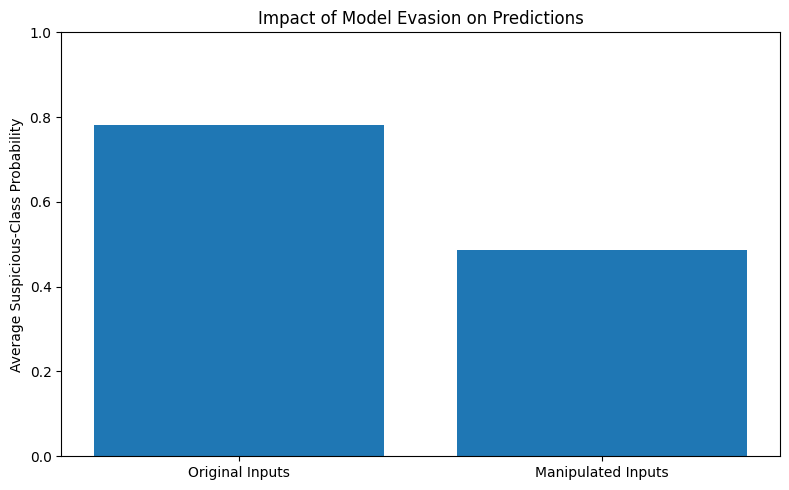

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(["Original Inputs", "Manipulated Inputs"], [original_probabilities.mean(), adversarial_probabilities.mean()])
plt.ylim(0, 1)
plt.ylabel("Average Suspicious-Class Probability")
plt.title("Impact of Model Evasion on Predictions")
plt.tight_layout()
plt.show()

---

## 🛡️ Apply the Defence

We'll now introduce two basic defensive checks:

1. Feature range validation.
2. Anomaly detection using Isolation Forest.

Feature validation checks whether incoming values fall outside the ranges observed during training. Isolation Forest attempts to identify unusual inputs based on patterns learned from the training dataset. These techniques may detect some manipulated inputs, but neither provides guaranteed protection against adversarial attacks.

In [6]:
training_min = X_train.min()
training_max = X_train.max()

def validate_features(samples):
    return ((samples < training_min) | (samples > training_max)).any(axis=1)

range_violations = validate_features(adversarial_samples)

anomaly_detector = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)
anomaly_detector.fit(X_train_scaled)

anomaly_predictions = anomaly_detector.predict(adversarial_scaled)
anomaly_flags = anomaly_predictions == -1
combined_flags = range_violations.to_numpy() | anomaly_flags

print(f"Range Violations: {range_violations.sum()}")
print(f"Anomalies Detected: {anomaly_flags.sum()}")
print(f"Total Flagged Inputs: {combined_flags.sum()}")

Range Violations: 1
Anomalies Detected: 14
Total Flagged Inputs: 14


---

## 🧪 Verify the Defence

Finally, we'll evaluate how effectively the defensive checks identify successful evasion attempts.

We'll measure the detection rate among successfully manipulated samples. We'll also check how frequently the same defensive controls flag the original, unmodified suspicious samples. This comparison helps reveal the trade-off between detecting manipulated inputs and incorrectly flagging legitimate model inputs.

In [7]:
successful_count = successful_attacks.sum()

detected_successful = np.sum(combined_flags & successful_attacks)
detection_rate = detected_successful / successful_count if successful_count else 0

original_range_flags = validate_features(target_samples).to_numpy()
original_anomaly_flags = anomaly_detector.predict(target_scaled) == -1
original_combined_flags = original_range_flags | original_anomaly_flags

original_flag_rate = original_combined_flags.mean()

print("🧪 Defense Verification")
print(f"Successful Evasions: {successful_count}")
print(f"Detected Successful Evasions: {detected_successful}")
print(f"Detection Rate: {detection_rate:.2%}")
print(f"Original Suspicious Samples Flagged: {original_flag_rate:.2%}")

🧪 Defense Verification
Successful Evasions: 202
Detected Successful Evasions: 14
Detection Rate: 6.93%
Original Suspicious Samples Flagged: 4.46%


We can visualise the defence results.

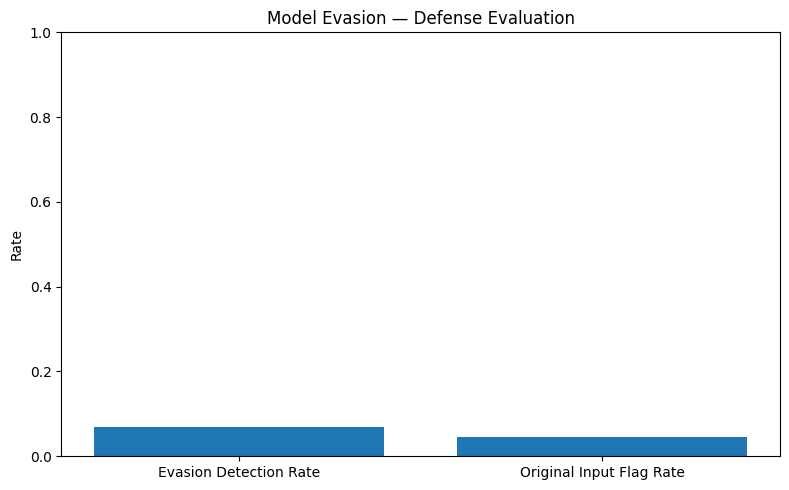

In [8]:
plt.figure(figsize=(8, 5))
plt.bar(["Evasion Detection Rate", "Original Input Flag Rate"], [detection_rate, original_flag_rate])
plt.ylim(0, 1)
plt.ylabel("Rate")
plt.title("Model Evasion — Defense Evaluation")
plt.tight_layout()
plt.show()

---

## 📌 Security Takeaways

- Model evasion manipulates inputs during inference without modifying the trained model.
- A correctly classified suspicious sample can sometimes be changed to produce a legitimate prediction.
- White-box attacks can use model parameters to identify effective perturbation directions.
- Attack success rate helps measure how vulnerable a classifier is to manipulated inputs.
- Feature validation and anomaly detection may identify some suspicious modifications.
- Defensive controls must be evaluated carefully because adversarial inputs can bypass simple validation techniques.

---

## 🚀 Final Note

A machine learning classifier can achieve good accuracy on normal data while remaining vulnerable to deliberately manipulated inputs.

Model evasion demonstrates why ML-based security systems must be evaluated against adversarial behaviour, not only ordinary test samples.

By measuring attack success and testing defensive controls, developers can better understand the limitations of their classifiers and work toward more robust AI/ML applications.

---